# Your first ANDES transit simulation with EXoPLORE

This notebook follows [Tutorial 1](../docs/tutorial.md#tutorial-1-run-the-reference-hd-189733-b-andes-simulation) and runs the same full ANDES simulation of HD 189733 b with EXoPLORE. Because we know the injected atmosphere and orbital parameters, we can follow the planetary signal through the analysis and check where it is recovered in velocity space.

Can we recover the Doppler-shifted H₂O spectrum of the planet from a realistic high-resolution transit observation? Let us see!

By the end, you should be able to run the reference simulation, inspect preparation steps and CCF products, follow the planet in the time–velocity CCF, understand how a Kp–Vrest map combines that signal, and interpret its recovered peak to assess if the planetary origin is plausible.

This notebook is intended to be run from an EXoPLORE source checkout. Save it under the repository’s notebooks/ directory and use the project environment described in the [installation guide](../docs/installation.md).

## The simulation

| Component | Reference experiment |
|---|---|
| Target / instrument | HD 189733 b / ANDES YJHK; all 76 orders |
| Resolving power | $R=\lambda/\Delta\lambda\simeq100{,}000$ |
| Observing sequence | One transit; 30 s exposures + 6 s readout |
| S/N model | ANDES exposure-time calculator (ETC) |
| Atmospheric spectra | petitRADTRANS; multiple species and gradual limb asymmetries |
| Chemistry | EasyChem equilibrium in the active morning and evening limb models |
| Search template | H₂O + H₂/He background; EasyChem enabled |
| Preparation | Blain24: [Blain, Sánchez-López & Mollière (2024), AJ, 167, 179](https://doi.org/10.3847/1538-3881/ad2c8b) |
| Seeds | Gaussian noise = 12345; throughput = 12345 |
| Retrieval | Disabled here; covered in tutorials (soon in a later Jupyter notebook as well)|

The simulation setup follows Sánchez-López, Pallé & Millán, *Resolving inhomogeneous hot and ultra-hot Jupiter atmospheres with ANDES: insights from simulated ELT observations*, **Accepted in A&A**. See the [citation reference](../docs/citations.md) and [ANDES ETC](https://andes-etc.brera.inaf.it/).

To connect with the [concepts primer](../docs/concepts.md#1-the-doppler-trick) section, let us remind that, in this ANDES simulation, its very high resolving power translates into one resolution element spanning $\Delta v\sim c/R\approx3$ km/s. During this transit, the planet moves by tens of km/s, crossing many ANDES resolution elements. Stellar and telluric (Earth-atmosphere) structures remain comparatively stationary in their appropriate rest frames, providing the Doppler separation we will use below.

In [1]:
# In this cell we will find the EXoPLORE folder, choose the configuration file,
# check that the input files are available, and make a new folder for our results.

# Path lets us build file locations without writing machine-specific path separators.
from pathlib import Path
# sys lets this notebook import its helper from the local checkout.
import sys

# Open this notebook inside your EXoPLORE checkout. Find its root so the same
# relative input paths work from either the repository or notebooks/ directory.
# Walk upward from the notebook directory to locate the EXoPLORE source tree.
REPO = next(folder for folder in (Path.cwd(), *Path.cwd().parents)
            if (folder / "src/exoplore/core/simulator.py").is_file())
# Add the checkout’s notebooks folder to Python’s module search path.
sys.path.insert(0, str(REPO / "notebooks"))
# Load readable notebook helpers for paths, displays and saved-run bookkeeping.
import _tutorial_support as tutorial

# False keeps the diagnostic plots and detection products without saving the
# large per-order matrices. Set True only if you need those numerical arrays 
# but watch for the very large files in that case!
# Keep False to skip large intermediate arrays while retaining plots and detection products.
SAVE_MATRICES = False

# Check the required local inputs and save a working copy of Tutorial 1's config
# in a NEW output directory. The reference JSON and scientific settings stay intact.
# To adapt the experiment, copy this JSON, edit your copy, and put its path here.
# Choose the reference JSON here, or point to your edited copy to adapt the experiment.
CONFIG_FILE = "configs/hd189733b_andes_transit_clean.json"
# Check external inputs, resolve local paths and reserve a fresh output directory; no simulation runs yet.
experiment = tutorial.prepare_tutorial(
    REPO, save_matrices=SAVE_MATRICES, source_config=CONFIG_FILE)
# Print the new directory so you know where this execution will write its products.
print("Inputs available. New output directory:", experiment.run_root)

# Create the optional plotting block if the reference file uses the defaults.
experiment.resolved.setdefault("plotting", {})
# Zoom the preparation diagnostic to this wavelength interval, in micrometres.
experiment.resolved["plotting"]["pipeline_steps_xlim_um"] = [0.953, 0.9545]
# Add a separate 10× deviation curve for illustration; keep the actual noisy curve.
experiment.resolved["plotting"]["pipeline_steps_noise_illustration_factor"] = 10.0
# Record these display settings in the run copy; atmospheric and noise settings stay unchanged.
tutorial.save_working_config(experiment)

Inputs available. New output directory: outputs/notebooks/01_first_ANDES_simulation/20261022T051821_233823Z


In [2]:
# In this cell we will print the name of the configuration file we are using,
# so you know which file to open when you want to change the experiment.

# The setup has loaded the reference JSON so we can inspect its actual values.
# The next tables use this source config.
# Show which source JSON was selected, using a path relative to the checkout.
print("Source configuration:", experiment.source_config.relative_to(REPO))

Source configuration: configs/hd189733b_andes_transit_clean.json


### Make this your own experiment

**Open [`configs/hd189733b_andes_transit_clean.json`](../configs/hd189733b_andes_transit_clean.json).** This is the file to explore when adapting the simulation. Copy it to, for example, `configs/my_andes_transit.json`, edit the copy, and set **`CONFIG_FILE` in the setup cell above** to that path. Restart the kernel and run from the beginning to load your changes into a fresh run directory.

Inside the JSON, these blocks control the experiment:

| What would you like to change? | Where to edit | Guidance |
|---|---|---|
| Planet and orbit | `planet.name`, `planet.parameter_file`; the linked file currently is [`planet_params/HD189733b.json`](../planet_params/HD189733b.json) | [Tutorial 2: a different planet](../docs/tutorial.md#tutorial-2-simulate-a-different-planet-wasp-76-b) explains the associated stellar and telluric inputs. Copy the planet file too when changing its physical parameters. |
| Wavelength coverage or instrument | `instrument.order_indices`, `instrument.name` | Use the four-order option below for a shorter ANDES test. You can also follow [Tutorial 4](../docs/tutorial.md#tutorial-4-carmenes-nir-simulation) for an instrument change. |
| Injected atmosphere | `atmosphere.morning_day` and `evening_day` for this `gradual` run; `planet_model` applies when limb asymmetries are disabled | [Tutorial 3](../docs/tutorial.md#tutorial-3-configure-the-forward-model-chemistry-temperature-clouds-and-limb-structure) covers chemistry, temperatures, clouds and limb structure. Here the active morning and evening models use EasyChem at their configured temperatures. The `_night` blocks are unused in `gradual` mode, although their EasyChem flags are also enabled. |
| Species to search for | `atmosphere.ccf_template` | This controls the search template separately from the injected atmosphere. |
| Cadence, nights and noise | `observation`, `noise` | Try the exposure time or number of nights; [Tutorial 5](../docs/tutorial.md#tutorial-5-multiple-nights) explains multi-night setups. Longer exposures also change the time sampling. |
| Preparation and velocity search | `pipeline`, `cross_correlation` | The [configuration reference](../docs/config_reference.md) explains the supported methods, velocity grids, weights and normalisation. |
| Local inputs and saved products | `paths`, `output` | See the [input guide](../docs/input_files.md) and [output reference](../docs/outputs.md); `SAVE_MATRICES` above controls optional large arrays in this notebook. |

Try things! Start by changing one setting, predict its effect, and compare the result with the reference. For example, shorten the order list, change the exposure time, or explore a limb temperature following Tutorial 3. Changing targets or instruments needs the matching inputs described in the tutorials.

The same guides are available online in [RTD Tutorials](https://exoplore.readthedocs.io/en/latest/tutorial.html) and the [RTD configuration reference](https://exoplore.readthedocs.io/en/latest/config_reference.html). The `resolved_config.json` and `overrides.json` saved beside each run show which values were actually used, including local-path and output overrides made by the notebook.

In [3]:
# In this cell we will look at the main settings: the instrument, exposure time,
# molecules to search for, preparation method, random seeds and orbital speed.

# json reads the planet’s physical and orbital parameters from its JSON file.
import json

# Inspect a few settings before starting the expensive calculation.
# Display the main observing and analysis settings before starting the calculation.
tutorial.show_table(["Setting", "Configured value"], [
    # Name of the reference instrument; the saved reference run includes all 76 orders.
    ["Instrument / orders", f"{experiment.reference['instrument']['name']} / all 76"],
    # Integration time and detector readout overhead, both in seconds.
    ["Exposure / readout (s)", (experiment.reference['observation']['exposure_time_seconds'],
                               experiment.reference['observation']['readout_time_seconds'])],
    # Species in the CCF template; these can differ from the injected atmosphere.
    ["Search species", experiment.reference['atmosphere']['ccf_template']['species']],
    # Configured preparation method applied before cross-correlation.
    ["Preparation", experiment.reference['pipeline']['name']],
    # Choice for how the two limbs contribute throughout transit.
    ["Limb contributions", experiment.reference['atmosphere']['limb_divisions']],
    # Independent controls for additive noise and throughput variation.
    ["Gaussian / throughput seeds", (experiment.resolved['noise']['noise_seed'],
                                     experiment.resolved['observation']['throughput_seed'])]])
# Read the linked planet file so we can compare the injected orbital motion with the recovered peak.
planet_data = json.loads((REPO / experiment.reference['planet']['parameter_file']).read_text())
# Print the configured orbital radial-velocity amplitude Kp in km/s.
print(f"Configured orbital Kp: {planet_data['kp_kms']:.3f} km/s")

Setting,Configured value
Instrument / orders,ANDES_YJHK / all 76
Exposure / readout (s),"(30.0, 6.0)"
Search species,"['H2', 'He', 'H2O']"
Preparation,Blain24
Limb contributions,gradual
Gaussian / throughput seeds,"(12345, 12345)"


Configured orbital Kp: 149.443 km/s


> **Short on time for a first test?** Try **orders 33–36** (`[33, 34, 35, 36]`; zero-based indices), spanning approximately **1.283–1.341 µm** in the Tutorial 1 ANDES ETC wavelength grid. Individual intervals are 1.283–1.296, 1.296–1.312, 1.310–1.326 and 1.326–1.341 µm, respectively. This wavelength interval is a suggested shorter test; its signal strength should be checked for the current atmosphere. A dedicated reduced-run timing benchmark is still needed before promising a 1–2 minute runtime.
>
> The saved outputs below show the full **76-order reference**. To run the smaller selection, uncomment both lines in the next cell before continuing. Only the run's working configuration is changed; the reference JSON stays intact. Reduced-order map S/N values should be assessed separately from the full reference.

The morning and evening limbs contribute differently as the transit progresses. In this `gradual` setup, EXoPLORE reads their temperatures, velocities and EasyChem settings from **`morning_day` and `evening_day`**. The two **`_night` blocks are unused in this mode**; they appear in the table because it lists all four stored region configurations. We will search the combined spectrum with one H₂O template.

In [4]:
# In this cell you can choose a shorter test using four spectral orders.
# Leave the lines below commented to run the full reference simulation.
# uncomment BOTH lines to process only these four orders.
# order_indices selects wavelength segments, and every other scientific setting stays the same.

# experiment.resolved["instrument"]["order_indices"] = [33, 34, 35, 36]
# tutorial.save_working_config(experiment)  # Save and record the selection for this run.

# Leave both lines commented to reproduce the complete 76-order tutorial 1 from RTD.

In [5]:
# In this cell we will look at the temperatures, velocities and chemistry
# assigned to the different regions of the planet’s atmosphere.

# Display each injected limb region’s temperature, wind velocity and chemistry.
tutorial.show_atmosphere(experiment.reference)

Injected species: H2, He, H2O, CH4, NH3, CO, H2S, HCN, Fe, Ca
Search species: H2, He, H2O
C/O: 0.41
Metallicity [dex]: 0.53


Configured region,Equilibrium temperature [K],Wind [km/s],Chemistry
morning_day,1000.0,-3.9,EasyChem
morning_night,1000.0,0.0,EasyChem
evening_day,1300.0,-3.9,EasyChem
evening_night,1300.0,0.0,EasyChem


In [6]:
# In this cell we will give our settings to EXoPLORE and check its summary.
# The simulation will start in the next code cell, after you have 
# the chance to review said settings!

# Import EXoPLORE’s configuration reader and validator.
from exoplore.config import SimulationConfig
# Import the public simulator that runs the forward model and analysis.
from exoplore.core.simulator import ExoploreSimulator

# Load the working config: local paths and file-saving controls are recorded.
# Also load the resolved run copy, including local inputs and any order 
# selection we made above.
config = SimulationConfig.from_json(experiment.config_path)
# "Summon" a simulator for these settings, and hope it works =P
simulator = ExoploreSimulator(config)
# Print the simulator’s own summary so you can inspect the planned experiment.
print(simulator.summary())
# Show the product directories, this is where your files are going to be created
dirs = simulator.output_dirs(create=False)
# Show the run identifier used in the filenames that we will inspect below.
run_name = simulator.simulation_name()


  EXoPLORE Simulation Summary
  Planet              : HD189733b
  Instrument          : ANDES_YJHK
  Event               : transit
  Nights              : 1
  Pipeline            : Blain24       (Blain, Sanchez-Lopez & Molliere 2024, AJ, 167, 179)
  Species             : ['H2', 'He', 'H2O', 'CH4', 'NH3', 'CO', 'H2S', 'HCN', 'Fe', 'Ca']
  EasyChem            : True
  C/O                 : 0.41
  Metallicity (log Z) : 0.53
  CCF v_max (km/s)    : 325.0
  Retrieval           : False
  Output root         : outputs/notebooks/01_first_ANDES_simulation/20261022T051821_233823Z



## Run EXoPLORE

The full calculation previously took about **28 minutes** on my local machine for 76 ANDES orders in YJHK bands. Leave it running! Verbose output goes to `run.log`. With `SAVE_MATRICES=False`, the full analysis still runs while optional arrays for intermediate steps stay unsaved.

In [7]:
# In this cell we will run the simulation and measure how long it takes.
# Detailed messages go into run.log, and we will also save the CCF 
# for a cool animation below.

# Import a clock for measuring the elapsed simulation time.
import time

# Choose a log file inside this run’s output directory.
LOG_PATH = experiment.run_root / "run.log"
# Record the start time using a clock intended for elapsed-time measurements.
started = time.perf_counter()
# Redirect verbose simulator messages into run.log while the indented block executes.
with tutorial.capture_run_log(LOG_PATH):
    # Run the complete observation: atmospheric spectra, noise, preparation, CCFs and detection map.
    simulator.run()  # Full forward simulation, preparation, CCFs and detection map.
    # Measure elapsed seconds immediately after the scientific run finishes.
    simulation_seconds = time.perf_counter() - started
    # Export real combined CCF products while this completed simulator is alive.
    # Save the real combined CCF, its axes and velocity conventions for the animation before discarding the simulator.
    CCF_PATH = tutorial.export_combined_ccf(simulator, experiment.run_root / "combined_ccf.npz")
# Show a short completion report with runtime and output location instead of the full log.
tutorial.show_run_completion(LOG_PATH, simulation_seconds, dirs['root'])

Simulation completed in 1669.4 s (27.82 min).
Log: outputs/notebooks/01_first_ANDES_simulation/20261022T051821_233823Z/run.log
Warning/notice lines: 2. Inspect run.log before changing scientific parameters.
src/exoplore/atmosphere/winds.py:130: RuntimeWarning: invalid value encountered in sqrt
src/exoplore/pipelines/blain24.py:142: RuntimeWarning: divide by zero encountered in divide
Output: outputs/notebooks/01_first_ANDES_simulation/20261022T051821_233823Z/HD189733b/ANDES_YJHK/transit/Blain24_withsignal_1nights_SNR_comb1_simdata_noisy_stdnoisex1


In [8]:
# In this cell we will open the saved CCF, check which orders were processed,
# and report how many exposures it contains and how large the saved file is.

# import and set up things
import numpy as np
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
plt.rcParams.update({key: plt.rcParamsDefault[key]
                     for key in ["font.family", "xtick.labelsize", "ytick.labelsize"]})

# Load the exported CCF arrays and metadata.
diagnostics = tutorial.load_ccf_bundle(CCF_PATH)
# Read which spectral orders actually contributed to the exported CCF.
orders = diagnostics.metadata['order_indices']
# Use the configured subset, or all 76 orders when no subset was specified.
expected_orders = config.instrument.order_indices or list(range(76))
# Stop here if the exported orders do not match the requested selection.
assert orders == list(expected_orders)
# Report the processed order count and number of exposures in the CCF bundle.
print(f"Completed {len(orders)} orders; {diagnostics.phase.size} exposures.")
# Report the CCF array dimensions and compressed file size in decimal MB.
print(f"Combined CCF: {diagnostics.ccf.shape}; saved bundle: {CCF_PATH.stat().st_size / 1e6:.2f} MB")

Completed 76 orders; 390 exposures.
Combined CCF: (651, 390); saved bundle: 1.95 MB


## Inspect spectral preparation

The raw spectra are dominated by stellar lines, telluric absorption and instrumental effects. The "Blain24" preparation pipeline (after Blain et al. 2024), fits wavelength-dependent throughput and log-flux behaviour with airmass (the relative path through Earth's atmosphere), removing much of this structure. Planetary lines, if present, are still usually too weak to be observed at this point and remain buried in the noise (injections can be done in EXoPLORE, hence we would add an additional panel to the bottom, where we could see these lines, see cell below. This helps illustrate the exercise a bit better!).

HD 189733 is a bright star, with **$J=6.073$ mag** ([NASA Exoplanet Archive](https://exoplanetarchive.ipac.caltech.edu/overview/HD189733)). The ETC-based noise model gives **order 0 a mean per-pixel S/N of approximately 423**, averaged over its 1,326 non-masked wavelength channels and all 390 exposures. At such high S/N, the actual noise is difficult to see on this plot's flux scale, so the noisy and noiseless curves almost overlap unless we zoom in more. The blue curve therefore shows **10× the noise deviations for illustration**, alongside the actual noisy spectrum in red.

[Open diagnostic PDF](../outputs/notebook01_zoom_noise_illustration/20261022T113257/plots_without_inset/pipeline_steps_reference.pdf)

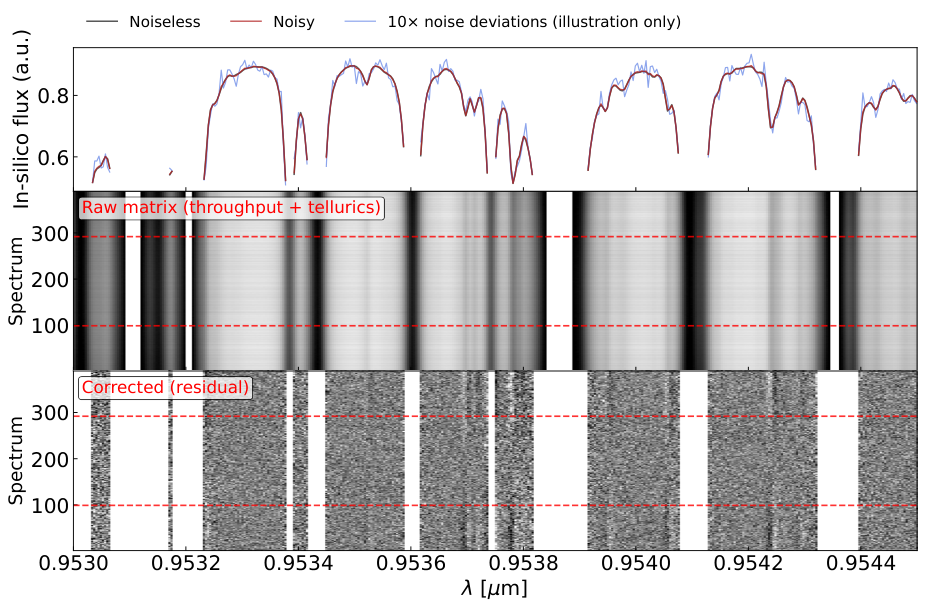

In [9]:
# In this cell we will display the preparation figure from the run.
# Use it to compare the original spectra with the spectra after preparation.

# Inspect the diagnostic already produced by this run.
# Locate the preparation diagnostic PDF produced by this run.
pipeline_steps_pdf = dirs['plots'] / f"pipeline_steps_{run_name}.pdf"
# Render that saved PDF inline; the helper embeds its image in the notebook output.
tutorial.show_saved_pdf(pipeline_steps_pdf, REPO / 'notebooks')

In this plot, rows are exposures and columns are wavelength channels. The top panel shows the actual noiseless and noisy spectra. We can now compare the raw middle panel with the prepared bottom panel to see which structures did the preparation pipeline remove, and which it did not. In all data analysis, real or in-silico, it is always the safest approach to inspect your data by eye, as some residuals may need manual masking, or even suggest a change in the full preparation choices! 
The red timing marks enclose the calculated in-transit exposures. Note the image panels use independent grey scales. **White bands mark masked spectral channels**, excluded from the analysis, for example because of strong telluric absorption and low S/N.

Exo-atmospheric lines, if present, are buried in the noise in the last panel. In the cell below, you can see them better in the bottom panel, occurring only in-transit, when we perform a 10x injection of the planet model.

Separate calculation: 10× planetary injection; order 0. The blue curve additionally shows 10× noise deviations for illustration.


[Open diagnostic PDF](../outputs/notebook01_injection10_illustration/20261022T113257/plots_without_inset/pipeline_steps_injection10.pdf)

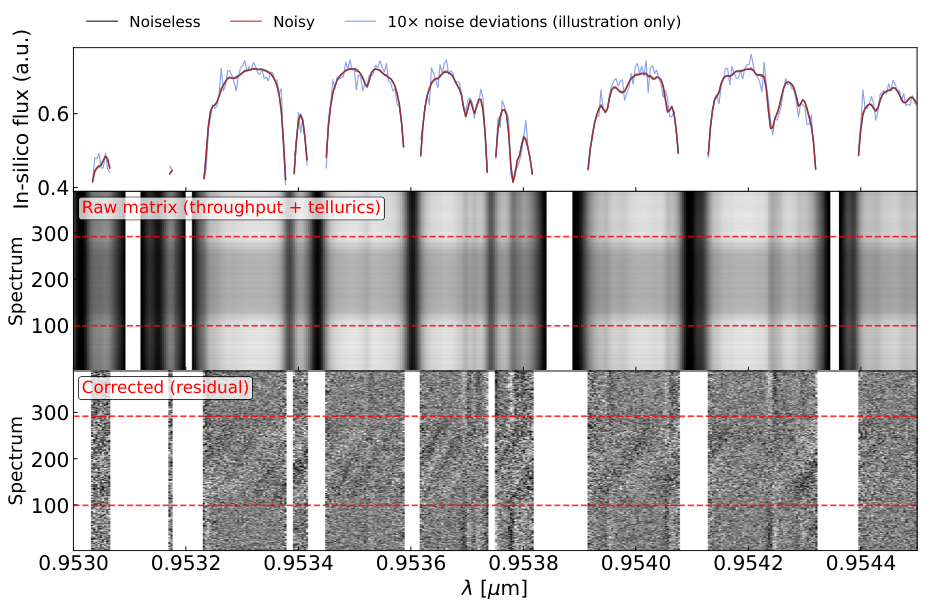

In [10]:
# In this cell we will run a short, SEPARATE order-0 simulation with a stronger
# planet signal, then show the same preparation diagnostic for comparison. This is
# just so we can see better where the planet signal, if present would be here.

# THE KNOB YOU WOULD HAVE TO CHANGE is observation.scale_injection in the simulation JSON.
# For this separate demonstration, change INJECTION_FACTOR below.

# For a new full simulation, open YOUR COPY of the JSON selected by CONFIG_FILE.
# Inside its "observation" block, set "scale_injection": 10.0 (or your chosen factor).
# 1.0 = reference injected signal; 10.0 = ten times that signal. Please be mindful
# of the factor. As something like 100x could trigger a masking of the full order
# in some cases and hence yield a failed simulation from EXoPLORE.

# Restart the kernel and run from the top to load a changed JSON into a new run.
# This changes the injected planetary spectrum; it is separate from the blue
# 10× noise-deviation curve, which only changes how the top panel is drawn.
INJECTION_FACTOR = 10.0
# Copy the current settings into a fresh run directory
injection_demo = tutorial.prepare_injection_demo(
    REPO, experiment, factor=INJECTION_FACTOR, order_index=0)
# Load the demonstration's own saved configuration using EXoPLORE interface.
injection_simulator = ExoploreSimulator(SimulationConfig.from_json(injection_demo.config_path))
# Keep messages from this additional calculation in its own log file.
with tutorial.capture_run_log(injection_demo.run_root / "run.log"):
    # Run only order 0 with the stronger planetary injection and the same noise settings.
    injection_simulator.run()
# Find the plots produced by the separate calculation.
injection_dirs = injection_simulator.output_dirs(create=False)
# Read the filename identifier assigned by EXoPLORE to this demonstration.
injection_name = injection_simulator.simulation_name()
# Locate its preparation figure
injection_plot = injection_dirs['plots'] / f"pipeline_steps_{injection_name}.pdf"

print(f"Separate calculation: {INJECTION_FACTOR:g}× planetary injection; order 0. "
      "The blue curve additionally shows 10× noise deviations for illustration.")
tutorial.show_saved_pdf(injection_plot, REPO / 'notebooks')

## Follow the H₂O pattern

Cross-correlation compares the prepared spectra with a template shifted through trial velocities, combining many individually weak H₂O lines. In the case of exo-atmospheric lines being buried in the noise after preparation (see above), CCF should achieve two things: 1) combine all that small extra absorption across hundreds of lines in the form of a CC peak; and 2) the CCF should only show a peak (significant enough, that is) when the trial velocities correspond to those expected for the exoplanet, with respect to the Earth, at the time of each exposure observation. In the cell below we have already summed the per-order CCFs over all 76 orders, which is done to increase as much as possible the significance of a possible signal (but by all means please inspect order-wise CCF matrices too to check the dependence of H2O detection strength as a function of wavelength!).

The plot below will stay in the **Earth-frame velocity** and represent velocities as a function of orbital phase ($\phi=0$ at mid-transit). For a circular orbit the reference motion is $v_p=K_p\sin(2\pi\phi)+V_{\rm sys}-V_{\rm BERV}$: systemic velocity just traces the relative velocity of that stellar system with respect to us (since we all move around the galactic center at different velocities) and hence adds an offset, whereas BERV is the Earth's barycentric velocity correction.

[Open original PDF](../outputs/notebooks/01_first_ANDES_simulation/20261022T051821_233823Z/HD189733b/ANDES_YJHK/transit/Blain24_withsignal_1nights_SNR_comb1_simdata_noisy_stdnoisex1/plots/CC_ERF_Blain24_withsignal_1nights_SNR_comb1_simdata_noisy_stdnoisex1.pdf)

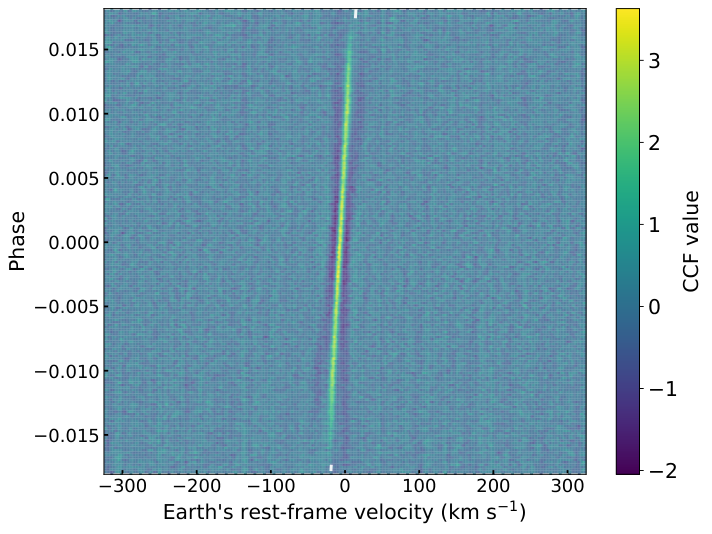

In [11]:
# In this cell we will display the CCF trail: how closely the spectra match
# the H₂O template at each trial velocity as the transit progresses.

# Show the order-combined CCF written by the same execution.
# Locate the saved Earth-frame CCF trail combining the selected orders.
ccf_trail_pdf = dirs['plots'] / f"CC_ERF_{run_name}.pdf"
# Render the existing CCF diagnostic inline without recomputing cross-correlations.
tutorial.show_saved_pdf(ccf_trail_pdf, REPO / 'notebooks')

An H2O feature is clearly observed changing velocity across transit, following the moving planetary line pattern (white dashed line). The wide plotted velocity range makes it appear steep. Colour shows the CCF value, with its amplitude describing template similarity.

Now let us align the exposures along trial orbital tracks (see animation below) and assess which combinations add more significantly.

## From the CCF trail to a Kp–Vrest map

Changing $K_p$ changes the trial track's slope; changing $V_{\rm rest}$ shifts it horizontally:

$$v_{\rm trial}(\phi)=K_p\sin(2\pi\phi)+V_{\rm sys}-V_{\rm BERV}+V_{\rm rest}.$$

The animation samples the **real CCF from this execution**. Orange segments show exposures being added; the right panel marks each completed trial's saved map value. It finishes by revealing the full map. We sample a few tracks for clarity, rather than animate every grid pixel.

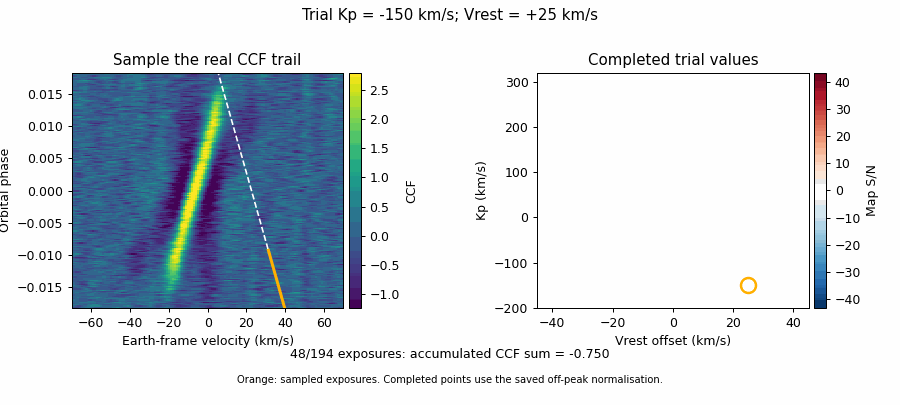

In [12]:
# In this cell we will make an animation from our saved CCF and detection map.
# We will see how changing the trial orbital motion changes the alignment 
# with the signal.
# To do this we reuse previous CCF-shifting and normalisation functions
# and locate the archive containing this run’s normalised Kp–Vrest map.
map_path = dirs['matrices'] / f"ccf_tot_sn_map_{run_name}.npz"
# Load its axes and statistic, and identify the strongest map pixel.
result = tutorial.load_detection_map(map_path)
# Build the GIF from this run’s CCF and map
animation = tutorial.animate_ccf_search(diagnostics, result, planet_data['kp_kms'], experiment.run_root / 'animation')
# Embed the GIF bytes in the notebook so viewing the saved animation needs no external image file.
tutorial.show_animation(animation.gif)

A track that follows the planetary trail samples a consistent H₂O-like pattern that only occurs during transit and follows clearly the expected exoplanet velocities with respect to the Earth during those exposures. Two very powerful diagnostics!

Peak map S/N = 43.17; Kp = 143 km/s; Vrest = -4 km/s


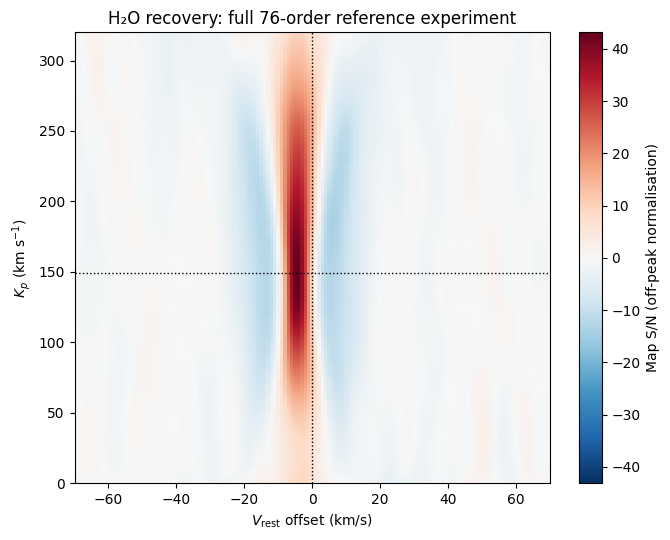

In [13]:
# In this cell we will show the Kp–Vrest map and print its strongest point.
# The reference crosshair marks the orbital solution computed for comparison, 
# without considering winds or additional sources of dynamics (hence you will
# see a shift, since we added injected limb velocity shifts above).

# We read the strongest pixel from the saved full map, then display that map.
print(f"Peak map S/N = {result.peak_snr:.2f}; Kp = {result.peak_kp:.0f} km/s; "
      f"Vrest = {result.peak_vrest:+.0f} km/s")
# Plot the saved map, label the selected orders and mark the configured orbital reference.
fig = tutorial.plot_detection_map(result, planet_data['kp_kms'], orders=orders)
# Display the map in this cell’s output.
display(fig)
# Close the figure after displaying it to avoid duplicate displays and release plotting resources.
plt.close(fig)

In [14]:
# In this cell we will put our measured peak values into the explanation below,
# so the text follows the result of your own run.

# Generate the interpretation from this execution's actual measured values.
# Insert this execution’s measured values into the interpretation below, rather than hard-coding a previous run.
display(Markdown(f"""The strongest pixel has **peak map S/N = {result.peak_snr:.2f}**, at
**Kp = {result.peak_kp:.0f} km/s** and **Vrest = {result.peak_vrest:+.0f} km/s**.
Compare this with the configured orbital amplitude **{planet_data['kp_kms']:.2f} km/s**,
marked by the black reference crosshair at nominal Vrest = 0. The broad ridge surrounding the signal reflects
similar alignment for nearby orbital tracks, and this an inevitable degeneracy of the method. 
The injected limb regions have different velocities, so the effective offset combines their contributions. That is, a single wind 
measurement here really has many contributions from different planetary regions (and rotation, e.g. whenever a limb shows stronger signal!). 
Map S/N uses EXoPLORE's row-wise off-peak mean and standard deviation, excluding
±25 km/s around each point.

The three slices below compare the nearby Kp rows with a much more distant track 
at approximately 20 km/s (which is still affected by the huge CCF values of the planet trail!)."""))

The strongest pixel has **peak map S/N = 43.17**, at
**Kp = 143 km/s** and **Vrest = -4 km/s**.
Compare this with the configured orbital amplitude **149.44 km/s**,
marked by the black reference crosshair at nominal Vrest = 0. The broad ridge surrounding the signal reflects
similar alignment for nearby orbital tracks, and this an inevitable degeneracy of the method. 
The injected limb regions have different velocities, so the effective offset combines their contributions. That is, a single wind 
measurement here really has many contributions from different planetary regions (and rotation, e.g. whenever a limb shows stronger signal!). 
Map S/N uses EXoPLORE's row-wise off-peak mean and standard deviation, excluding
±25 km/s around each point.

The three slices below compare the nearby Kp rows with a much more distant track 
at approximately 20 km/s (which is still affected by the huge CCF values of the planet trail!).

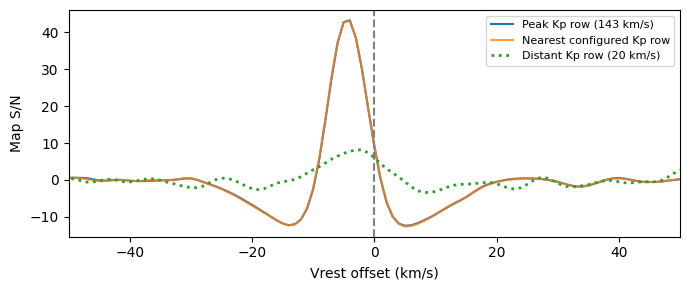

In [15]:
# Compare the peak and configured Kp rows with a distant track near 20 km/s.

# Compare the peak row and the grid row nearest the configured Kp.
# Find the sampled Kp row closest to the configured orbital amplitude.
nominal_row = np.argmin(abs(result.kp_grid - planet_data['kp_kms']))
distant_row = np.argmin(abs(result.kp_grid - 20.0))
# Plot velocity slices through the peak row and that nearby orbital-reference row from the same map.
fig = tutorial.plot_velocity_slices(result.v_rest, result.snr_map[:, result.kp_index],
                          result.snr_map[:, nominal_row], result.peak_kp)
ax = fig.axes[0]
ax.plot(result.v_rest, result.snr_map[:, distant_row], ls=':', lw=2,
        label=f'Distant Kp row ({result.kp_grid[distant_row]:.0f} km/s)')
ax.legend(fontsize=8)
# Display the three profiles together so their shapes can be compared.
display(fig)
# Close the displayed figure to avoid a duplicate automatic display.
plt.close(fig)

**Final remark**
With both the Gaussian-noise and throughput seeds fixed, the stochastic realisation is reproducible, but please consider that end-to-end floating-point results may still differ at machine-precision level.

The final cell below records the configuration, software, seeds and products we have used in this notebook. If you wish, you can continue with the [RTD tutorials](../docs/tutorial.md), or consult [configuration](../docs/config_reference.md), [inputs](../docs/input_files.md), [outputs](../docs/outputs.md), [installation](../docs/installation.md) and [data acknowledgements](../docs/data_acknowledgements.md) as needed! And by all means contact alexsl@iaa.es for any suggestions!

In [16]:
# In this cell we will save a record of the settings, files, software version
# and results, so you can later check how this particular run was made.

# Save provenance; detailed bookkeeping stays in the notebook helper.
# Collect the source and resolved configs, overrides, seeds, software revision, runtime and recovered result.
record = tutorial.write_reproducibility(
    REPO, experiment.source_config, experiment.reference, experiment.config_path, experiment.resolved, experiment.run_root,
    experiment.overrides, experiment.path_sources, simulation_seconds, orders, SAVE_MATRICES, result)
# Record the location of the exported combined CCF bundle.
record['ccf_bundle'] = str(CCF_PATH)
# Record the compressed bundle’s size in bytes.
record['ccf_bundle_bytes'] = CCF_PATH.stat().st_size
# Record the CCF array’s in-memory size in bytes, excluding axes and metadata.
record['ccf_matrix_bytes'] = diagnostics.ccf.nbytes
# Include the animation’s frame count, file size and reconstruction checks in the run record.
record['animation'] = animation.record
# Write the updated record as readable JSON beside the simulation products.
(experiment.run_root / 'reproducibility.json').write_text(json.dumps(record, indent=2) + '\n');

Reproducibility,Recorded value
EXoPLORE version,0.2.0
Git revision,f655fc52c5ef1f2cb07e838fa82027d2ec1c55c6
Gaussian / throughput seeds,12345 / 12345
Source config,configs/hd189733b_andes_transit_clean.json
Resolved config,outputs/notebooks/01_first_ANDES_simulation/20261022T051821_233823Z/resolved_config.json
Runtime,1669.4 s (27.82 min)
Output directory,outputs/notebooks/01_first_ANDES_simulation/20261022T051821_233823Z
SAVE_MATRICES,False
Output files / size,25 files; 14.65 MB (13.97 MiB)
Reference integrity check,Parsed JSON equals the initially loaded reference
